In [2]:
import numpy as np
import pickle as pkl
from hdbscan import HDBSCAN
from umap import UMAP

# Load artifacts

In [3]:
X_embed = np.load('../data/processed/embeddings.npy')

with open('../data/processed/kmeans_model.pkl', 'rb') as file:
    km = pkl.load(file)

print('Artifacts loaded successfully ✅')

Artifacts loaded successfully ✅


# Dimensionality reduction: UMAP

In [4]:
umap_reducer = UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)

X_umap = umap_reducer.fit_transform(X_embed)

/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/opt/miniconda3/envs/myenv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


# Fit: HDBSCAN

Because your SentenceTransformer vectors are L2-normalized, Euclidean distance mathematically mirrors Cosine similarity, making HDBSCAN highly effective out of the box. min_cluster_size=15 tells the algorithm: "Do not create a cluster unless you find at least 15 tickets tightly packed together."

Plot saved as hdbscan_clusters.png at 300 DPI.


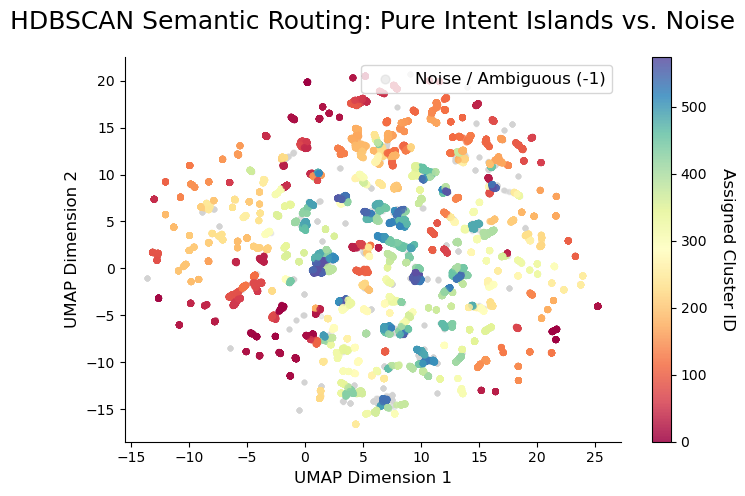

In [7]:
import matplotlib.pyplot as plt

clusterer = HDBSCAN(
    min_samples=5,
    min_cluster_size=15,
    metric='euclidean',
    cluster_selection_method='eom'
)

labels = clusterer.fit_predict(X_umap)
labels

plt.figure(figsize=(8, 5))

# Create boolean masks to separate noise from clustered points
noise_mask = (labels == -1)
clustered_mask = (labels >= 0)

# Plot the Noise Ocean (Small, semi-transparent grey dots)
plt.scatter(
    X_umap[noise_mask, 0], 
    X_umap[noise_mask, 1], 
    color='lightgrey', 
    s=10, 
    alpha=0.4, 
    label='Noise / Ambiguous (-1)'
)

# Plot the Pure Intent Islands (Bright, distinct colors)
scatter = plt.scatter(
    X_umap[clustered_mask, 0], 
    X_umap[clustered_mask, 1], 
    c=labels[clustered_mask], 
    cmap='Spectral', # Spectral provides distinct, bright colors
    s=25, 
    alpha=0.85,
    edgecolors='none'
)

# Formatting for Medium Article
plt.title("HDBSCAN Semantic Routing: Pure Intent Islands vs. Noise", fontsize=18, pad=20)
plt.xlabel("UMAP Dimension 1", fontsize=12)
plt.ylabel("UMAP Dimension 2", fontsize=12)

# Add colorbar for the valid clusters
cbar = plt.colorbar(scatter)
cbar.set_label('Assigned Cluster ID', rotation=270, labelpad=20, fontsize=12)

# Remove top and right borders for a cleaner look
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.legend(markerscale=2, fontsize=12, loc='upper right')

# Save as a high-resolution image for your article
plt.savefig("hdbscan_clusters.png", dpi=300, bbox_inches='tight')
print("Plot saved as hdbscan_clusters.png at 300 DPI.")

plt.show()

In [8]:
unique_labels = len(np.unique(labels))
unique_labels - (1 if -1 in labels else 0) # subtracting value 1 (Not a list comprehension) if -1 labels (noise) are present.

576

# Noise ratio

In [9]:
n_noise = list(labels).count(-1)
# noise ratio
noise_ratio = n_noise / unique_labels
noise_ratio

3.835355285961872